# Лабораторная работа №1: Кластеризация

**Выполнил:** Бушуев Никита

**Вариант:** 1

**Набор данных:** `1heart.csv`

**Цель работы:** изучить методы кластеризации, выполнить подготовку и стандартизацию данных, подобрать количество кластеров для KMeans и агломеративного метода Ward, описать полученные группы и сравнить качество разбиений.

## 1. Загрузка и обзор данных

Подключаем библиотеки для работы с таблицами, визуализации и кластеризации.

In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from scipy.cluster.hierarchy import dendrogram
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score, calinski_harabasz_score, davies_bouldin_score,
    adjusted_rand_score, adjusted_mutual_info_score,
    homogeneity_score, completeness_score, v_measure_score,
    fowlkes_mallows_score
)
from threadpoolctl import threadpool_limits

threadpool_limits(limits=1)
pd.set_option('display.precision', 6)
pd.set_option('display.max_columns', 20)
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.family'] = 'DejaVu Sans'

In [38]:
df = pd.read_csv('1heart.csv')

print(f'Размер набора: {df.shape[0]} строк, {df.shape[1]} столбцов')
display(df.head(10))
df.info()
print('\nКоличество пропусков:')
print(df.isna().sum())
print('\nКоличество дубликатов:', df.duplicated().sum())

Размер набора: 925 строк, 12 столбцов


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140.0,289,0,Normal,172.0,N,0.0,Up,0
1,49,F,NAP,160.0,180,0,Normal,156.0,N,1.0,Flat,1
2,37,M,ATA,130.0,283,0,ST,98.0,N,0.0,Up,0
3,48,F,ASY,138.0,214,0,Normal,108.0,Y,1.5,Flat,1
4,54,M,NAP,150.0,195,0,Normal,122.0,N,0.0,Up,0
5,39,M,NAP,120.0,339,0,Normal,170.0,N,0.0,Up,0
6,45,F,ATA,130.0,237,0,Normal,170.0,N,0.0,Up,0
7,54,M,ATA,110.0,208,0,Normal,142.0,N,0.0,Up,0
8,37,M,ASY,140.0,207,0,Normal,130.0,Y,1.5,Flat,1
9,48,F,ATA,120.0,284,0,Normal,120.0,N,0.0,Up,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 925 entries, 0 to 924
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             925 non-null    int64  
 1   Sex             925 non-null    object 
 2   ChestPainType   925 non-null    object 
 3   RestingBP       923 non-null    float64
 4   Cholesterol     924 non-null    object 
 5   FastingBS       925 non-null    int64  
 6   RestingECG      924 non-null    object 
 7   MaxHR           924 non-null    float64
 8   ExerciseAngina  925 non-null    object 
 9   Oldpeak         925 non-null    float64
 10  ST_Slope        925 non-null    object 
 11  HeartDisease    925 non-null    int64  
dtypes: float64(3), int64(3), object(6)
memory usage: 86.8+ KB

Количество пропусков:
Age               0
Sex               0
ChestPainType     0
RestingBP         2
Cholesterol       1
FastingBS         0
RestingECG        1
MaxHR             1
ExerciseAngina    0

Получено 925 строк и 12 столбцов. В исходной таблице 5 пустых ячеек и 3 полных дубликата. Столбец `Cholesterol` имеет тип `object`, хотя должен содержать числовые значения. Перед построением моделей проверим его содержимое и категории строковых признаков.

In [39]:
print('Категории строковых признаков:')
for column in df.select_dtypes(include='object').columns:
    if column != 'Cholesterol':
        print(column, df[column].value_counts(dropna=False).to_dict())

cholesterol = pd.to_numeric(df['Cholesterol'], errors='coerce')
invalid_cholesterol = df['Cholesterol'].notna() & cholesterol.isna()
print('\nНекорректные значения Cholesterol:')
display(df.loc[invalid_cholesterol, ['Cholesterol']])

Категории строковых признаков:
Sex {'M': 729, 'F': 195, 'Ma': 1}
ChestPainType {'ASY': 497, 'NAP': 207, 'ATA': 175, 'TA': 46}
RestingECG {'Normal': 557, 'LVH': 189, 'ST': 178, nan: 1}
ExerciseAngina {'N': 553, 'Y': 372}
ST_Slope {'Flat': 461, 'Up': 400, 'Down': 63, 'UP': 1}

Некорректные значения Cholesterol:


,Cholesterol
922,a241


В `Cholesterol` найдена строка `a241`. В `Sex` встречается значение `Ma` вместо `M`, а в `ST_Slope` значение `UP` вместо `Up`. Эти ошибки формата необходимо обработать до удаления повторных записей и расчета расстояний.

## 2. Предварительная обработка данных

### 2.1 Исправление форматов и дубликатов

Исправляем явные опечатки в категориях и преобразуем числовые столбцы через `pd.to_numeric(errors='coerce')`. Значение `a241` станет пропуском: считать его равным 241 без проверки исходного измерения нельзя.

После исправления форматов удаляем полные дубликаты. Принимаем допущение, что полностью совпадающие записи являются повторной загрузкой одного наблюдения. Идентификаторов пациентов в файле нет, поэтому проверить это допущение невозможно. Исходный индекс сохраняем для сопоставления строк, но не используем как признак.

In [40]:
numeric_features = ['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak']
categorical_features = ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']
target = 'HeartDisease'

for column in categorical_features:
    df[column] = df[column].astype('string').str.strip()

df['Sex'] = df['Sex'].replace({'Ma': 'M'})
df['ST_Slope'] = df['ST_Slope'].replace({'UP': 'Up'})

for column in numeric_features + [target]:
    df[column] = pd.to_numeric(df[column], errors='coerce')

print('Дубликатов после исправления форматов:', df.duplicated().sum())
print('Индексы удаляемых строк:', df.index[df.duplicated()].tolist())
df = df.drop_duplicates().copy()
print('Количество строк после удаления:', len(df))

Дубликатов после исправления форматов: 4
Индексы удаляемых строк: [918, 919, 920, 924]
Количество строк после удаления: 921


После исправления форматов обнаружены 4 дубликата. Один дополнительный повтор выявлен благодаря замене `Ma` и `UP`. Удалены строки с исходными индексами 918, 919, 920 и 924. Осталось 921 наблюдение.

### 2.2 Обработка пропусков

Нулевые `RestingBP` и `Cholesterol` считаем невалидными измерениями и заменяем пропусками. Нули в `FastingBS` и `Oldpeak` допустимы, поэтому сохраняем их.

Числовые пропуски заполняем медианами, категориальные модами. Для заполнения не используем `HeartDisease`. Отрицательные значения `Oldpeak` не удаляем автоматически, поскольку один только знак не доказывает ошибку.

In [41]:
for column in ['RestingBP', 'Cholesterol']:
    df.loc[df[column] <= 0, column] = np.nan

missing_before = df.isna().sum()
medians = df[numeric_features].median()
modes = df[categorical_features].mode().iloc[0]

for column in numeric_features:
    df[column] = df[column].fillna(medians[column])
for column in categorical_features:
    df[column] = df[column].fillna(modes[column])

missing_table = pd.DataFrame({
    'Пропусков до заполнения': missing_before,
    'Пропусков после заполнения': df.isna().sum()
})
display(missing_table)
print('Медианы числовых признаков:')
print(medians)
print('\nМоды категориальных признаков:')
print(modes)
print('\nОтрицательных значений Oldpeak:', (df['Oldpeak'] < 0).sum())

,Пропусков до заполнения,Пропусков после заполнения
Age,0,0
Sex,0,0
ChestPainType,0,0
RestingBP,3,0
Cholesterol,174,0
FastingBS,0,0
RestingECG,1,0
MaxHR,1,0
ExerciseAngina,0,0
Oldpeak,0,0


Медианы числовых признаков:
Age             54.0
RestingBP      130.0
Cholesterol    237.0
FastingBS        0.0
MaxHR          138.0
Oldpeak          0.6
dtype: float64

Моды категориальных признаков:
Sex                    M
ChestPainType        ASY
RestingECG        Normal
ExerciseAngina         N
ST_Slope            Flat
Name: 0, dtype: string

Отрицательных значений Oldpeak: 13


В `RestingBP` заполнены 3 значения медианой 130: 2 пустые ячейки и 1 ноль. В `Cholesterol` заполнены 174 значения медианой 237: пустая ячейка, строка `a241` и 172 нуля. В `MaxHR` заполнен 1 пропуск медианой 138, в `RestingECG` 1 пропуск модой `Normal`.

После обработки пропуски отсутствуют, 13 отрицательных значений `Oldpeak` сохранены. Замена одной медианой уменьшает его вариативность и влияет на геометрию будущих кластеров.

## 3. Выделение целевой переменной

Отделяем `HeartDisease` в `y`. Для кластеризации используем только шесть числовых признаков в `X`. Пять строковых признаков не кодируем и оставляем для описания пациентов. Бинарный `FastingBS` уже представлен числами 0 и 1, поэтому включаем его в модель.

Целевая переменная не участвует в стандартизации, обучении и подборе количества кластеров. Используем ее только для раскраски исходных данных и последующего сравнения найденных групп с известными классами.

In [42]:
X = df[numeric_features].astype(float).copy()
y = df[target].astype(int).copy()

print('Размер матрицы признаков:', X.shape)
print('Признаки модели:', X.columns.tolist())
print('\nРаспределение HeartDisease:')
display(y.value_counts().sort_index().rename_axis('HeartDisease').to_frame('Объектов'))
print('Описательная статистика числовых признаков:')
display(X.describe().T)

Размер матрицы признаков: (921, 6)
Признаки модели: ['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak']

Распределение HeartDisease:


,Объектов
HeartDisease,
0,412
1,509


Описательная статистика числовых признаков:


,count,mean,std,min,25%,50%,75%,max
Age,921.0,53.499457,9.431921,28.0,47.0,54.0,60.0,77.0
RestingBP,921.0,132.562432,17.958789,80.0,120.0,130.0,140.0,200.0
Cholesterol,921.0,243.270358,53.443506,85.0,214.0,237.0,267.0,603.0
FastingBS,921.0,0.232356,0.422564,0.0,0.0,0.0,0.0,1.0
MaxHR,921.0,136.834962,25.450867,60.0,120.0,138.0,156.0,202.0
Oldpeak,921.0,0.885993,1.065522,-2.6,0.0,0.6,1.5,6.2


Матрица `X` содержит 921 строку и 6 признаков. В `y` находятся 412 записей класса 0 и 509 записей класса 1. Наличие двух известных классов не означает, что алгоритм обязательно должен выделить два кластера. Число групп выбираем по структуре признаков, а не по целевой разметке.

## 4. Матрица диаграмм рассеяния

Строим `pairplot` по всем числовым признакам модели. Значения `HeartDisease` выделяем разными цветами. На диагонали используем гистограммы, чтобы корректно отобразить в том числе бинарный `FastingBS`.

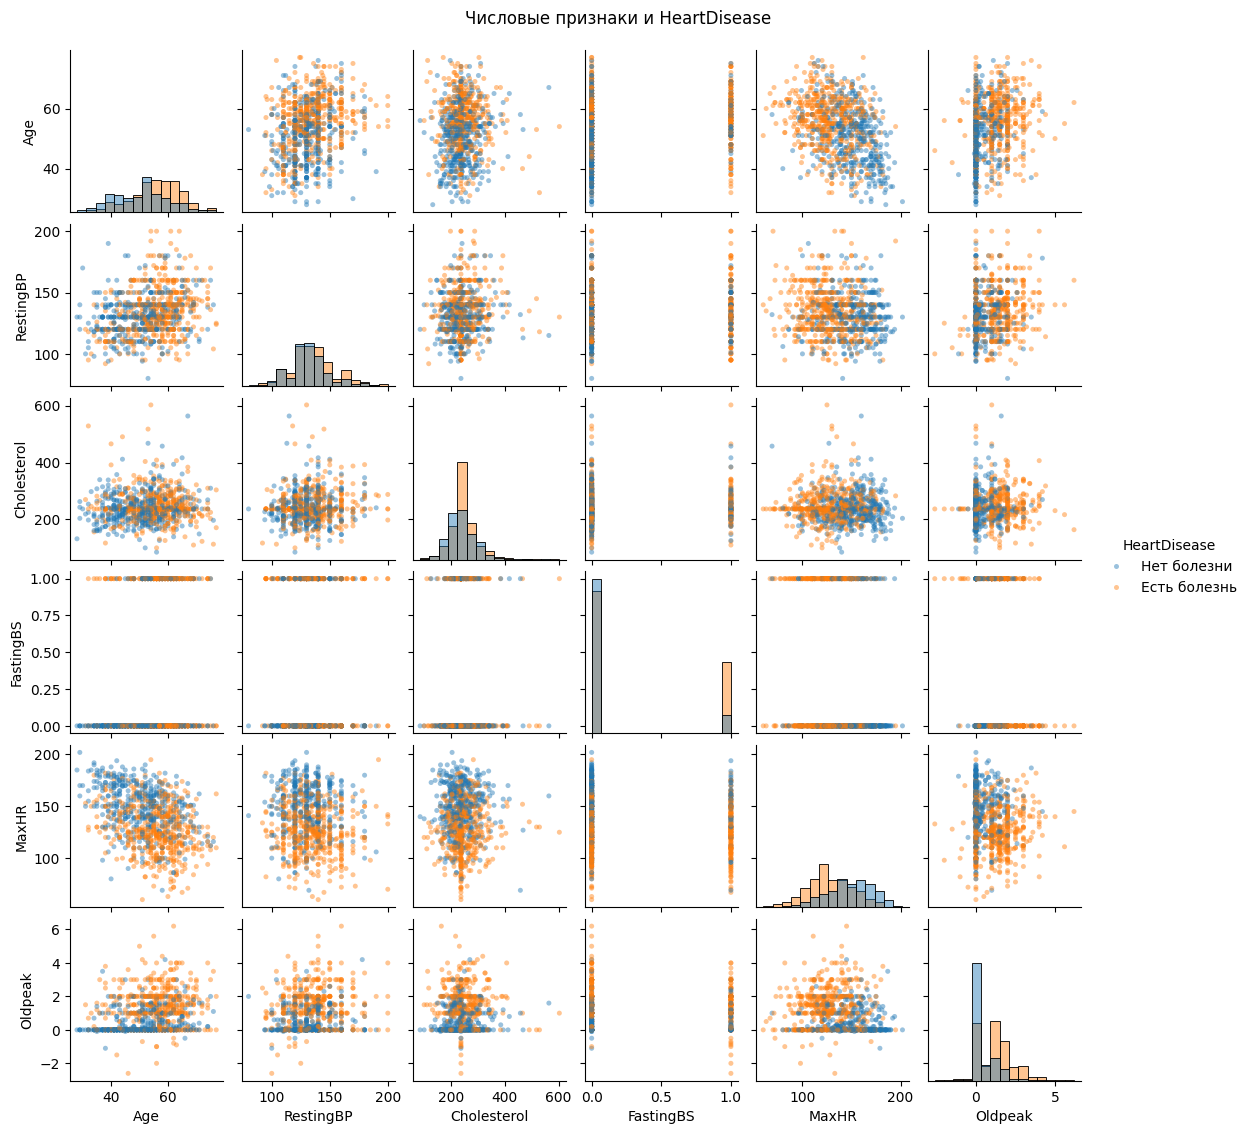

In [43]:
pairplot_data = X.copy()
pairplot_data[target] = y.map({0: 'Нет болезни', 1: 'Есть болезнь'})

grid = sns.pairplot(
    pairplot_data, vars=numeric_features, hue=target,
    diag_kind='hist', height=1.85,
    plot_kws={'alpha': 0.45, 's': 13, 'linewidth': 0},
    diag_kws={'alpha': 0.45, 'bins': 15}
)
grid.figure.suptitle('Числовые признаки и HeartDisease', y=1.02)
plt.show()

На графиках известные классы заметно перекрываются. Возраст, максимальная ЧСС и `Oldpeak` различаются между классами, но не дают полного разделения. Полосы на диаграммах `FastingBS` связаны с его бинарностью, а скопление значений `Cholesterol` около 237 частично вызвано заполнением пропусков.

## 5. Стандартизация данных

Применяем `StandardScaler` к шести признакам из `X`. Из каждого значения вычитается среднее, затем результат делится на стандартное отклонение. В проверке используем `ddof = 0`, как в StandardScaler.

In [44]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

scaler_parameters = pd.DataFrame({
    'Признак': numeric_features,
    'Среднее до': scaler.mean_,
    'Std до': scaler.scale_,
    'Среднее после': X_scaled.mean(axis=0),
    'Std после': X_scaled.std(axis=0, ddof=0)
})
display(scaler_parameters)

,Признак,Среднее до,Std до,Среднее после,Std после
0,Age,53.499457,9.426800,-2.314471e-16,1.0
1,RestingBP,132.562432,17.949037,-2.700217e-16,1.0
2,Cholesterol,243.270358,53.414484,-2.661642e-16,1.0
3,FastingBS,0.232356,0.422335,4.628943e-17,1.0
4,MaxHR,136.834962,25.437047,-3.857452e-16,1.0
5,Oldpeak,0.885993,1.064943,1.080087e-16,1.0


После преобразования средние значения близки к 0, стандартные отклонения равны 1. Устранено различие масштабов, но распределения не становятся автоматически нормальными. Далее обе модели обучаем на одной матрице `X_scaled`.

Стандартизированный `FastingBS` также получает единичную дисперсию. Поэтому бинарный показатель может заметно влиять на расстояния и состав групп. При описании кластеров возвращаемся к исходным единицам измерения.

## 6. Кластеризация KMeans

### 6.1 Подбор количества кластеров

Перебираем `k` от 1 до 10 и рассчитываем инерцию. Для `k` от 2 до 10 дополнительно вычисляем средний силуэт, Calinski-Harabasz и Davies-Bouldin. Основным критерием выбора считаем максимальный силуэт. Для Calinski-Harabasz предпочтительнее большее значение, для Davies-Bouldin меньшее.

Фиксируем `random_state = 42` и `n_init = 30`. При каждом `k` KMeans выбирает лучший результат из 30 инициализаций по наименьшей инерции. Разные метрики могут рекомендовать разное количество групп.

In [45]:
k_values = range(1, 11)
kmeans_models = {}
kmeans_results = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=30, algorithm='lloyd')
    labels = model.fit_predict(X_scaled)
    kmeans_models[k] = model
    result = {'k': k, 'Инерция': model.inertia_}
    if k > 1:
        result['Silhouette'] = silhouette_score(X_scaled, labels)
        result['Calinski-Harabasz'] = calinski_harabasz_score(X_scaled, labels)
        result['Davies-Bouldin'] = davies_bouldin_score(X_scaled, labels)
    kmeans_results.append(result)

kmeans_results = pd.DataFrame(kmeans_results)
best_k_kmeans = int(kmeans_results.loc[kmeans_results['Silhouette'].idxmax(), 'k'])
display(kmeans_results.round(6))
print('Выбранное количество кластеров:', best_k_kmeans)

,k,Инерция,Silhouette,Calinski-Harabasz,Davies-Bouldin
0,1,5526.000000,NaN,NaN,NaN
1,2,4421.255856,0.190849,229.631557,1.874580
2,3,3725.558599,0.213878,221.819784,1.666455
3,4,3382.925854,0.212730,193.638986,1.586429
4,5,3088.360819,0.189868,180.749402,1.542140
5,6,2873.603398,0.193620,168.917434,1.584824
6,7,2690.932781,0.185552,160.492764,1.533272
7,8,2557.727913,0.171614,151.363828,1.535041
8,9,2443.310043,0.163410,143.832199,1.496281
9,10,2351.230949,0.161176,136.676143,1.513187


Выбранное количество кластеров: 3


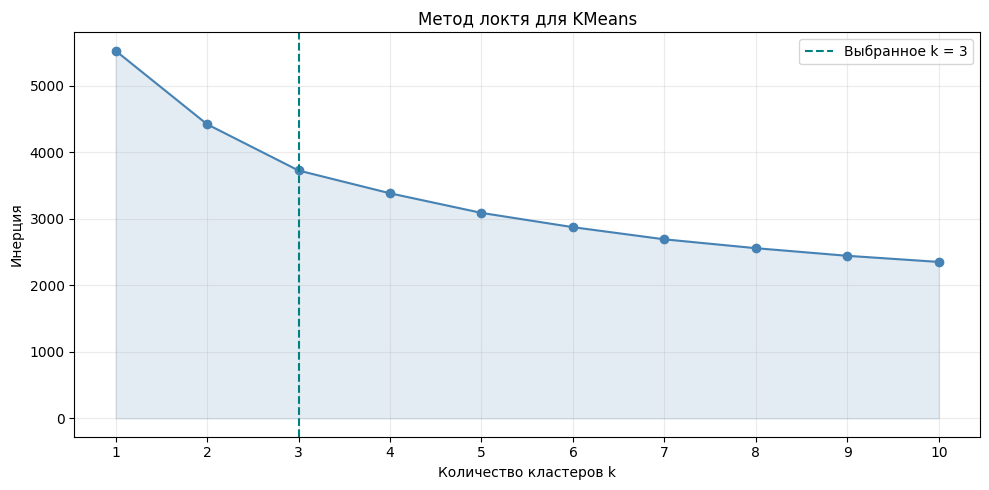

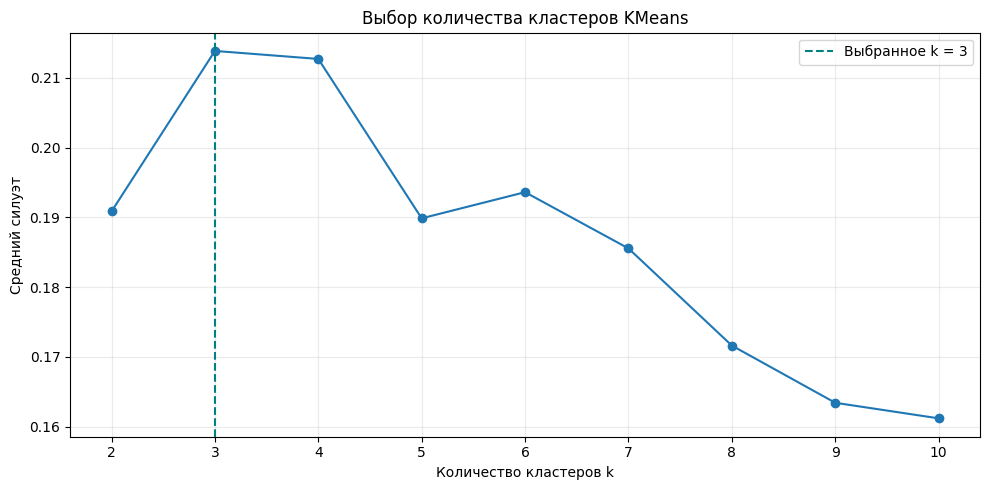

In [46]:
plt.figure()
plt.plot(kmeans_results['k'], kmeans_results['Инерция'], marker='o', color='steelblue')
plt.fill_between(kmeans_results['k'], kmeans_results['Инерция'], alpha=0.15, color='steelblue')
plt.axvline(best_k_kmeans, color='teal', linestyle='--', label=f'Выбранное k = {best_k_kmeans}')
plt.xticks(list(k_values))
plt.xlabel('Количество кластеров k')
plt.ylabel('Инерция')
plt.title('Метод локтя для KMeans')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

plt.figure()
plt.plot(kmeans_results['k'][1:], kmeans_results['Silhouette'][1:], marker='o')
plt.axvline(best_k_kmeans, color='teal', linestyle='--', label=f'Выбранное k = {best_k_kmeans}')
plt.xticks(range(2, 11))
plt.xlabel('Количество кластеров k')
plt.ylabel('Средний силуэт')
plt.title('Выбор количества кластеров KMeans')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

Максимальный силуэт получен при `k = 3`: 0.213878. Для `k = 4` он равен 0.212730, разница составляет всего 0.001148. Выбираем три группы по основному критерию, но их небольшое преимущество не доказывает существование единственного правильного разбиения.

Инерция уменьшается плавно, однозначного резкого локтя нет. Calinski-Harabasz максимален при `k = 2`, а Davies-Bouldin минимален при `k = 9`. Выбор трех кластеров относится к принятому критерию силуэта, а не к согласованному решению всех метрик.

### 6.2 Модель для трех кластеров

Берем модель с выбранным `k` из выполненного перебора. Выводим метки первых объектов, численности групп и центры. Координаты центров возвращаем в исходные единицы через `inverse_transform`.

In [47]:
kmeans = kmeans_models[best_k_kmeans]
kmeans_clusters = kmeans.labels_
kmeans_centers = scaler.inverse_transform(kmeans.cluster_centers_)

print('Метки первых 20 объектов:')
print(kmeans_clusters[:20])
print('\nКоличество объектов в кластерах:')
display(pd.Series(kmeans_clusters).value_counts().sort_index().rename_axis('Кластер').to_frame('Объектов'))
print('Центры в исходных единицах:')
display(pd.DataFrame(kmeans_centers, columns=numeric_features).rename_axis('Кластер').T)
print(f'Инерция: {kmeans.inertia_:.6f}')

Метки первых 20 объектов:
[2 2 2 0 0 2 2 2 2 2 2 0 2 2 2 2 2 2 0 2]

Количество объектов в кластерах:


,Объектов
Кластер,
0,353
1,206
2,362


Центры в исходных единицах:


Кластер,0,1,2
Age,5.868839e+01,57.543689,46.138122
RestingBP,1.379263e+02,135.830097,125.472376
Cholesterol,2.500822e+02,246.131068,235.000000
FastingBS,8.604228e-16,1.000000,0.022099
MaxHR,1.231728e+02,129.990291,154.052486
Oldpeak,1.351558e+00,1.039320,0.344751


Инерция: 3725.558599


Сформированы 3 кластера с численностями 353, 206 и 362 объекта. Инерция равна 3725.558599. Номера групп условны: они не соответствуют значениям `HeartDisease`, а их перестановка не изменяет качество разбиения.

## 7. Анализ кластеров KMeans

Добавляем метки к очищенной таблице и рассчитываем средние значения числовых признаков через `groupby`. Отдельно выводим численности и долю `HeartDisease = 1` внутри каждой группы. Эта доля только описывает готовое разбиение и не используется при обучении.

In [48]:
kmeans_data = df.assign(KMeans_cluster=kmeans_clusters)
kmeans_means = kmeans_data.groupby('KMeans_cluster')[numeric_features].mean()
kmeans_summary = kmeans_data.groupby('KMeans_cluster').agg(
    Объектов=(target, 'size'),
    С_болезнью=(target, 'sum'),
    Доля_болезни=(target, 'mean')
)
kmeans_summary['Доля болезни, %'] = kmeans_summary.pop('Доля_болезни') * 100

print('Средние значения признаков:')
display(kmeans_means.T)
print('Численности и доли болезни:')
display(kmeans_summary)
print('Примеры объектов каждого кластера:')
display(kmeans_data.groupby('KMeans_cluster').head(3)[numeric_features + [target, 'KMeans_cluster']])

Средние значения признаков:


KMeans_cluster,0,1,2
Age,58.688385,57.543689,46.138122
RestingBP,137.926346,135.830097,125.472376
Cholesterol,250.082153,246.131068,235.000000
FastingBS,0.000000,1.000000,0.022099
MaxHR,123.172805,129.990291,154.052486
Oldpeak,1.351558,1.039320,0.344751


Численности и доли болезни:


,Объектов,С_болезнью,"Доля болезни, %"
KMeans_cluster,,,
0,353,250,70.821530
1,206,164,79.611650
2,362,95,26.243094


Примеры объектов каждого кластера:


,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,KMeans_cluster
0,40,140.0,289.0,0,172.0,0.0,0,2
1,49,160.0,180.0,0,156.0,1.0,1,2
2,37,130.0,283.0,0,98.0,0.0,0,2
3,48,138.0,214.0,0,108.0,1.5,1,0
4,54,150.0,195.0,0,122.0,0.0,0,0
11,58,136.0,164.0,0,99.0,2.0,1,0
36,65,140.0,306.0,1,87.0,1.5,1,1
38,48,120.0,177.0,1,148.0,0.0,0,1
52,45,140.0,224.0,1,122.0,0.0,0,1


Кластер 0 содержит 353 пациента. Средний возраст равен 58.69 года, давление 137.93, холестерин 250.08, максимальная ЧСС 123.17, `Oldpeak` 1.35. У всех `FastingBS = 0`. Болезнь отмечена у 250 пациентов, доля составляет 70.82%. Здесь наиболее низкая средняя максимальная ЧСС и наиболее высокий средний `Oldpeak` среди найденных групп.

Кластер 1 содержит 206 пациентов. Средний возраст равен 57.54 года, давление 135.83, максимальная ЧСС 129.99, `Oldpeak` 1.04. У всех `FastingBS = 1`. Болезнь отмечена у 164 пациентов, доля составляет 79.61%. Этот кластер особенно явно определяется бинарным показателем сахара.

Кластер 2 содержит 362 пациента. Средний возраст равен 46.14 года, давление 125.47, максимальная ЧСС 154.05, `Oldpeak` 0.34. Значение `FastingBS = 1` встречается у 2.21% группы. Болезнь отмечена у 95 пациентов, доля составляет 26.24%. Это более молодая группа с высокой максимальной ЧСС, но она не состоит исключительно из здоровых пациентов.

### 7.1 Категориальные характеристики

Строковые признаки не участвовали в модели, но их можно использовать для описания полученных групп. Рассчитываем доли мужчин, бессимптомной боли `ASY`, стенокардии при нагрузке и плоского наклона ST. Среднее для строковых категорий не определено, поэтому сначала переводим выбранные значения в индикаторы 0 и 1.

In [49]:
def categorical_profile(data, labels):
    profile = pd.DataFrame({
        'Кластер': labels,
        'Мужчины, %': data['Sex'].eq('M').astype(float) * 100,
        'ASY, %': data['ChestPainType'].eq('ASY').astype(float) * 100,
        'Стенокардия Y, %': data['ExerciseAngina'].eq('Y').astype(float) * 100,
        'ST Flat, %': data['ST_Slope'].eq('Flat').astype(float) * 100
    })
    return profile.groupby('Кластер').mean()


kmeans_profile = categorical_profile(df, kmeans_clusters)
display(kmeans_profile.round(2))

,"Мужчины, %","ASY, %","Стенокардия Y, %","ST Flat, %"
Кластер,,,,
0,80.74,67.71,61.19,66.57
1,87.38,66.02,47.09,61.17
2,72.10,33.70,16.30,27.62


Доли стенокардии при нагрузке и плоского ST в кластере 2 ниже, чем в двух других группах. Категориальные характеристики дополняют описание, но не объясняют механизм построения кластеров: расстояния рассчитывались только по числовым признакам.

## 8. Метрики качества KMeans

Вычисляем внутренние метрики на стандартизированной матрице и внешние метрики относительно `HeartDisease`. Для внутренних оценок истинная разметка не нужна. ARI, AMI, однородность, полнота, V-мера и индекс Фаулкса-Мэллоуса показывают разные стороны согласованности кластеров с известными классами.

Определяем функцию расчета метрик, чтобы затем применить ее и к Ward. Номера кластеров не приравниваем к диагнозам. Эти оценки не являются точностью медицинской диагностики.

In [50]:
def clustering_metrics(data, labels, true_labels):
    return {
        'Silhouette': silhouette_score(data, labels),
        'Calinski-Harabasz': calinski_harabasz_score(data, labels),
        'Davies-Bouldin': davies_bouldin_score(data, labels),
        'ARI': adjusted_rand_score(true_labels, labels),
        'AMI': adjusted_mutual_info_score(true_labels, labels),
        'Homogeneity': homogeneity_score(true_labels, labels),
        'Completeness': completeness_score(true_labels, labels),
        'V-measure': v_measure_score(true_labels, labels),
        'Fowlkes-Mallows': fowlkes_mallows_score(true_labels, labels)
    }


kmeans_metrics = clustering_metrics(X_scaled, kmeans_clusters, y)
display(pd.Series(kmeans_metrics, name='KMeans, k = 3').to_frame())

,"KMeans, k = 3"
Silhouette,0.213878
Calinski-Harabasz,221.819784
Davies-Bouldin,1.666455
ARI,0.146329
AMI,0.131908
Homogeneity,0.169921
Completeness,0.109238
V-measure,0.132984
Fowlkes-Mallows,0.508034


Силуэт KMeans равен 0.213878, Calinski-Harabasz 221.819784, Davies-Bouldin 1.666455. Отделенность групп ограничена, что согласуется с перекрытием наблюдений на графиках. ARI равен 0.146329, AMI 0.131908: найденные кластеры связаны с известной разметкой, но не воспроизводят ее полностью.

## 9. Агломеративная кластеризация Ward

### 9.1 Построение дендрограммы

Применяем агломеративный метод к той же матрице `X_scaled`. Ward последовательно объединяет группы с минимальным приростом внутрикластерной суммы квадратов. Используем евклидово расстояние.

Строим полное дерево через `AgglomerativeClustering`. По `children_`, `distances_` и количеству объектов в ветвях формируем матрицу для дендрограммы. Для читаемости показываем последние 25 ветвей, хотя дерево рассчитано по всем 921 наблюдению. Числа в скобках обозначают размеры свернутых ветвей.

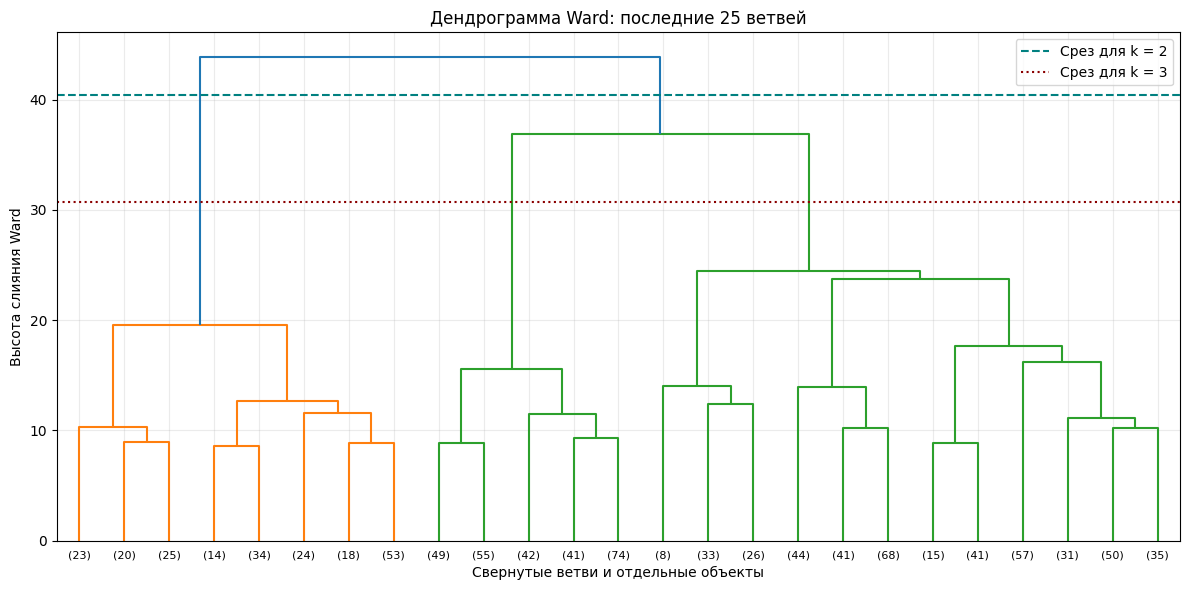

,k,Нижняя высота,Верхняя высота,Разрыв
0,2,36.894848,43.897774,7.002926
1,3,24.459139,36.894848,12.435709
2,4,23.749916,24.459139,0.709223
3,5,19.515002,23.749916,4.234914
4,6,17.621480,19.515002,1.893523
5,7,16.178259,17.621480,1.443220
6,8,15.606286,16.178259,0.571973
7,9,13.983577,15.606286,1.622709
8,10,13.894540,13.983577,0.089037


In [51]:
ward_tree = AgglomerativeClustering(
    n_clusters=None, distance_threshold=0,
    linkage='ward', metric='euclidean', compute_distances=True
).fit(X_scaled)

n_samples = len(X)
counts = np.zeros(len(ward_tree.children_))
for i, children in enumerate(ward_tree.children_):
    for child in children:
        if child < n_samples:
            counts[i] += 1
        else:
            counts[i] += counts[child - n_samples]

linkage_matrix = np.column_stack([
    ward_tree.children_, ward_tree.distances_, counts
]).astype(float)

cut_2 = (linkage_matrix[-2, 2] + linkage_matrix[-1, 2]) / 2
cut_3 = (linkage_matrix[-3, 2] + linkage_matrix[-2, 2]) / 2

plt.figure(figsize=(12, 6))
dendrogram(linkage_matrix, truncate_mode='lastp', p=25, leaf_rotation=0,
           leaf_font_size=8, color_threshold=cut_2)
plt.axhline(cut_2, color='teal', linestyle='--', label='Срез для k = 2')
plt.axhline(cut_3, color='darkred', linestyle=':', label='Срез для k = 3')
plt.xlabel('Свернутые ветви и отдельные объекты')
plt.ylabel('Высота слияния Ward')
plt.title('Дендрограмма Ward: последние 25 ветвей')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

merge_gaps = []
for k in range(2, 11):
    lower = linkage_matrix[-k, 2]
    upper = linkage_matrix[-k + 1, 2]
    merge_gaps.append({'k': k, 'Нижняя высота': lower,
                       'Верхняя высота': upper, 'Разрыв': upper - lower})
display(pd.DataFrame(merge_gaps).round(6))

Последние высоты слияния равны примерно 24.46, 36.89 и 43.90. Наиболее широкий из рассмотренных верхних интервалов соответствует трем группам: от 24.46 до 36.89. Срез между 36.89 и 43.90 дает две группы.

Дендрограмма допускает обсуждение двух и трех кластеров. Окончательное число групп выбираем по тому же основному критерию среднего силуэта, что и для KMeans. Визуальный срез дополняет анализ, но не заменяет расчет метрик.

### 9.2 Подбор количества кластеров

Перебираем `k` от 2 до 10, рассчитываем три внутренние метрики и выбираем максимальный силуэт. Целевую переменную при подборе не используем.

,k,Silhouette,Calinski-Harabasz,Davies-Bouldin
0,2,0.238900,194.074436,1.687546
1,3,0.177830,194.403874,1.742075
2,4,0.180707,165.790330,1.702111
3,5,0.168861,154.386819,1.725608
4,6,0.167478,142.131338,1.776019
5,7,0.160120,132.533117,1.752040
6,8,0.144652,124.777657,1.720699
7,9,0.113661,119.112637,1.775459
8,10,0.117447,113.531378,1.713685


Выбранное количество кластеров: 2


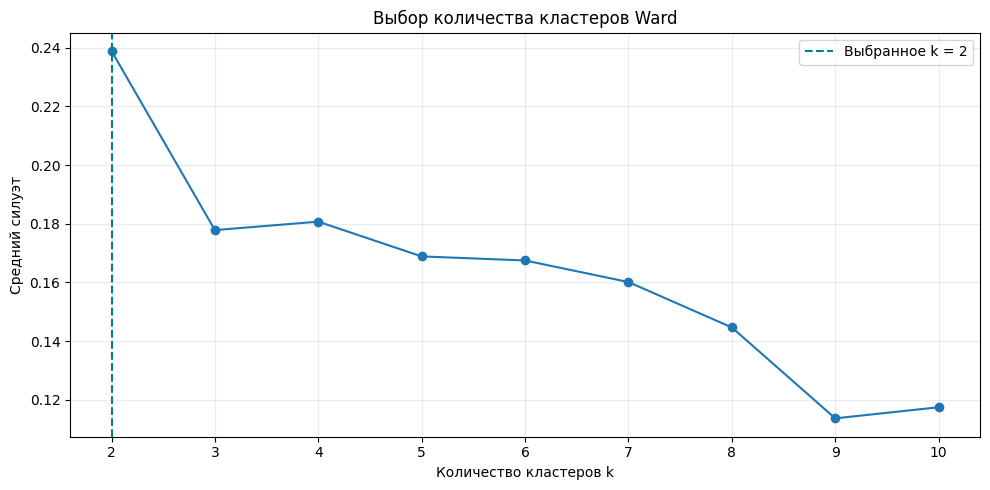

In [52]:
ward_models = {}
ward_results = []

for k in range(2, 11):
    model = AgglomerativeClustering(n_clusters=k, linkage='ward', metric='euclidean')
    labels = model.fit_predict(X_scaled)
    ward_models[k] = model
    ward_results.append({
        'k': k,
        'Silhouette': silhouette_score(X_scaled, labels),
        'Calinski-Harabasz': calinski_harabasz_score(X_scaled, labels),
        'Davies-Bouldin': davies_bouldin_score(X_scaled, labels)
    })

ward_results = pd.DataFrame(ward_results)
best_k_ward = int(ward_results.loc[ward_results['Silhouette'].idxmax(), 'k'])
ward = ward_models[best_k_ward]
ward_clusters = ward.labels_

display(ward_results.round(6))
print('Выбранное количество кластеров:', best_k_ward)

plt.figure()
plt.plot(ward_results['k'], ward_results['Silhouette'], marker='o')
plt.axvline(best_k_ward, color='teal', linestyle='--', label=f'Выбранное k = {best_k_ward}')
plt.xticks(range(2, 11))
plt.xlabel('Количество кластеров k')
plt.ylabel('Средний силуэт')
plt.title('Выбор количества кластеров Ward')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

Максимальный силуэт Ward получен при `k = 2`: 0.238900. При `k = 3` он равен 0.177830. Выбор двух групп основан на силуэте, хотя самый широкий верхний разрыв дендрограммы соответствует трем. Разные критерии описывают разные свойства структуры, поэтому их выводы не обязаны совпадать.

### 9.3 Анализ групп и метрики

Добавляем метки Ward к очищенной таблице. Через `groupby` рассчитываем средние числовых признаков, размеры кластеров и доли болезни. Затем используем те же функции для категориального описания и оценки качества, что и для KMeans.

In [53]:
ward_data = df.assign(Ward_cluster=ward_clusters)
ward_means = ward_data.groupby('Ward_cluster')[numeric_features].mean()
ward_summary = ward_data.groupby('Ward_cluster').agg(
    Объектов=(target, 'size'),
    С_болезнью=(target, 'sum'),
    Доля_болезни=(target, 'mean')
)
ward_summary['Доля болезни, %'] = ward_summary.pop('Доля_болезни') * 100
ward_profile = categorical_profile(df, ward_clusters)
ward_metrics = clustering_metrics(X_scaled, ward_clusters, y)

print('Средние значения признаков:')
display(ward_means.T)
print('Численности и доли болезни:')
display(ward_summary)
print('Категориальные характеристики:')
display(ward_profile.round(2))
print('Примеры объектов каждого кластера:')
display(ward_data.groupby('Ward_cluster').head(3)[numeric_features + [target, 'Ward_cluster']])
print('Метрики качества:')
display(pd.Series(ward_metrics, name='Ward, k = 2').to_frame())

Средние значения признаков:


Ward_cluster,0,1
Age,52.463380,56.985782
RestingBP,131.880282,134.857820
Cholesterol,243.685915,241.872038
FastingBS,0.004225,1.000000
MaxHR,138.580282,130.962085
Oldpeak,0.855352,0.989100


Численности и доли болезни:


,Объектов,С_болезнью,"Доля болезни, %"
Ward_cluster,,,
0,710,341,48.028169
1,211,168,79.620853


Категориальные характеристики:


,"Мужчины, %","ASY, %","Стенокардия Y, %","ST Flat, %"
Кластер,,,,
0,76.20,50.56,38.87,47.18
1,87.68,65.40,45.50,59.72


Примеры объектов каждого кластера:


,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,Ward_cluster
0,40,140.0,289.0,0,172.0,0.0,0,0
1,49,160.0,180.0,0,156.0,1.0,1,0
2,37,130.0,283.0,0,98.0,0.0,0,0
36,65,140.0,306.0,1,87.0,1.5,1,1
38,48,120.0,177.0,1,148.0,0.0,0,1
52,45,140.0,224.0,1,122.0,0.0,0,1


Метрики качества:


,"Ward, k = 2"
Silhouette,0.238900
Calinski-Harabasz,194.074436
Davies-Bouldin,1.687546
ARI,0.023677
AMI,0.061179
Homogeneity,0.055275
Completeness,0.070620
V-measure,0.062013
Fowlkes-Mallows,0.581673


Кластер 0 содержит 710 пациентов. Средний возраст равен 52.46 года, давление 131.88, холестерин 243.69, максимальная ЧСС 138.58, `Oldpeak` 0.86. Только 3 пациента имеют `FastingBS = 1`. Болезнь отмечена у 341 пациента, доля составляет 48.03%, то есть группа включает значительное число записей обоих классов.

Кластер 1 содержит 211 пациентов. Средний возраст равен 56.99 года, давление 134.86, холестерин 241.87, максимальная ЧСС 130.96, `Oldpeak` 0.99. У всех `FastingBS = 1`. Болезнь отмечена у 168 пациентов, доля составляет 79.62%. Разбиение в основном связано с бинарным показателем сахара.

Силуэт равен 0.238900, Calinski-Harabasz 194.074436, Davies-Bouldin 1.687546. ARI составляет 0.023677, AMI 0.061179. Геометрическая отделенность по силуэту выше, чем у выбранного KMeans, но согласованность с диагнозом по ARI и AMI ниже.

## 10. Сравнение методов

Сопоставляем выбранные разбиения: KMeans с тремя группами и Ward с двумя. Внутренние метрики вычислены в одном пространстве, внешние относительно одной целевой разметки. Дополнительно сравниваем внутренние показатели при одинаковых `k = 2` и `k = 3`, чтобы отдельно увидеть влияние числа кластеров.

Внутренние метрики:


,"KMeans, k = 3","Ward, k = 2"
Silhouette,0.213878,0.238900
Calinski-Harabasz,221.819784,194.074436
Davies-Bouldin,1.666455,1.687546


Внешние метрики:


,"KMeans, k = 3","Ward, k = 2"
ARI,0.146329,0.023677
AMI,0.131908,0.061179
Homogeneity,0.169921,0.055275
Completeness,0.109238,0.070620
V-measure,0.132984,0.062013
Fowlkes-Mallows,0.508034,0.581673


Сравнение при одинаковом числе кластеров:


,Метод,k,Silhouette,Calinski-Harabasz,Davies-Bouldin
0,KMeans,2,0.190849,229.631557,1.874580
1,Ward,2,0.238900,194.074436,1.687546
2,KMeans,3,0.213878,221.819784,1.666455
3,Ward,3,0.177830,194.403874,1.742075


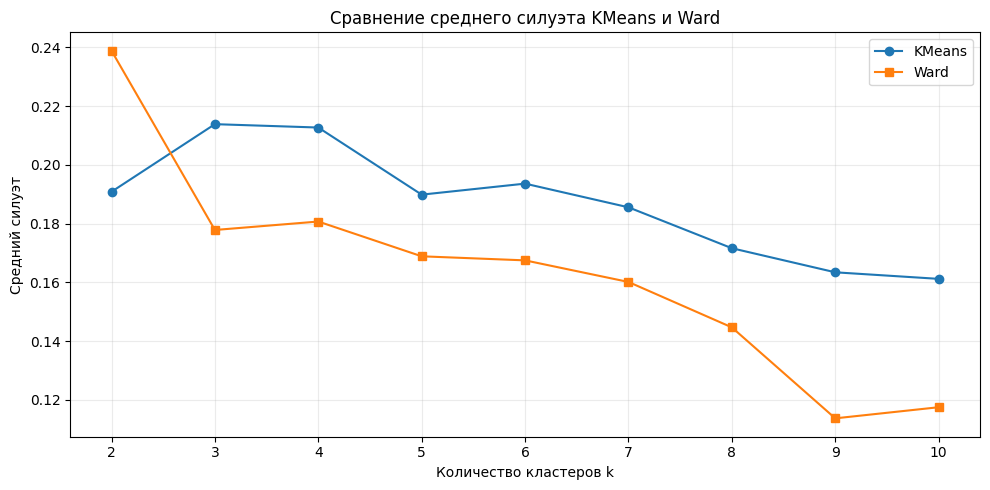

In [54]:
comparison = pd.DataFrame({
    'KMeans, k = 3': kmeans_metrics,
    'Ward, k = 2': ward_metrics
})
print('Внутренние метрики:')
display(comparison.loc[['Silhouette', 'Calinski-Harabasz', 'Davies-Bouldin']])
print('Внешние метрики:')
display(comparison.loc[['ARI', 'AMI', 'Homogeneity', 'Completeness', 'V-measure', 'Fowlkes-Mallows']])

same_k = []
for k in [2, 3]:
    for name, results in [('KMeans', kmeans_results), ('Ward', ward_results)]:
        row = results.loc[results['k'] == k].iloc[0]
        same_k.append({
            'Метод': name, 'k': k,
            'Silhouette': row['Silhouette'],
            'Calinski-Harabasz': row['Calinski-Harabasz'],
            'Davies-Bouldin': row['Davies-Bouldin']
        })

print('Сравнение при одинаковом числе кластеров:')
display(pd.DataFrame(same_k).round(6))

plt.figure()
plt.plot(kmeans_results['k'][1:], kmeans_results['Silhouette'][1:], marker='o', label='KMeans')
plt.plot(ward_results['k'], ward_results['Silhouette'], marker='s', label='Ward')
plt.xticks(range(2, 11))
plt.xlabel('Количество кластеров k')
plt.ylabel('Средний силуэт')
plt.title('Сравнение среднего силуэта KMeans и Ward')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

Ward с двумя кластерами имеет более высокий силуэт: 0.238900 против 0.213878. KMeans с тремя кластерами имеет более высокий Calinski-Harabasz: 221.819784 против 194.074436, и немного меньший Davies-Bouldin: 1.666455 против 1.687546. Внутренние метрики не дают единого безусловного победителя.

По ARI и AMI согласованность с `HeartDisease` выше у KMeans. При этом индекс Фаулкса-Мэллоуса выше у Ward. Складывать разные метрики или выбирать алгоритм только по количеству выигранных показателей некорректно: они описывают разные свойства разбиения.

Для описания нескольких возрастных и нагрузочных профилей пациентов в этой работе предпочтительнее KMeans с тремя группами. Если задача состоит именно в максимизации среднего силуэта в выбранном пространстве признаков, предпочтителен Ward с двумя группами. Его преимущество по силуэту не означает более точную диагностику.

## Вывод

Подготовлен набор из 921 наблюдения. Исправлены ошибки формата, удалены 4 полных дубликата, заполнены пропуски и невалидные нулевые измерения. Для моделей использованы 6 числовых признаков после стандартизации. Целевая переменная и исходный индекс в матрицу признаков не включались.

По максимуму силуэта среди значений `k` от 2 до 10 выбраны 3 кластера KMeans и 2 кластера Ward. Силуэт составил 0.213878 и 0.238900 соответственно. Дендрограмма допускает разные уровни среза, поэтому решение о двух группах Ward связано с выбранным критерием, а не с единственным возможным визуальным разбиением.

KMeans выделяет более молодую группу с высокой максимальной ЧСС, группу с низкой максимальной ЧСС и высоким средним `Oldpeak`, а также группу с `FastingBS = 1`. Ward преимущественно разделяет пациентов по `FastingBS`. Для более подробного описания пациентов выбран KMeans, а для максимизации среднего силуэта в данном эксперименте предпочтителен Ward.

Выводы ограничены исключением пяти строковых признаков, влиянием стандартизированного `FastingBS` и заменой 18.89% значений `Cholesterol` одной медианой. Устойчивость к другим способам обработки и повторным выборкам не проверялась. Найденные кластеры не являются диагнозами, качество применения к новым пациентам не оценивалось.